# Time-Series Modeling

## Loading Data

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import scipy

datapath = "../week6/collected_data_spring_2.csv"

df = pd.read_csv(datapath)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

print(df.shape)

MAX_REPLICA_COUNT = df['Count'].max() + 1

replica_graphs = []

def get_replica_row(replica_num, group):
    if len(group) >= replica_num:
        return group.iloc[replica_num-1:replica_num]

grouped = df.groupby('Timestamp')

node_stats = grouped.apply(lambda x: x.iloc[0]).reset_index(drop=True)
pod_stats = grouped.apply(lambda x: x.iloc[1]).reset_index(drop=True)

node_stats['Memory'] = node_stats['Memory'].str.split("Mi").apply(lambda x: int(x[0]))

(55599, 6)


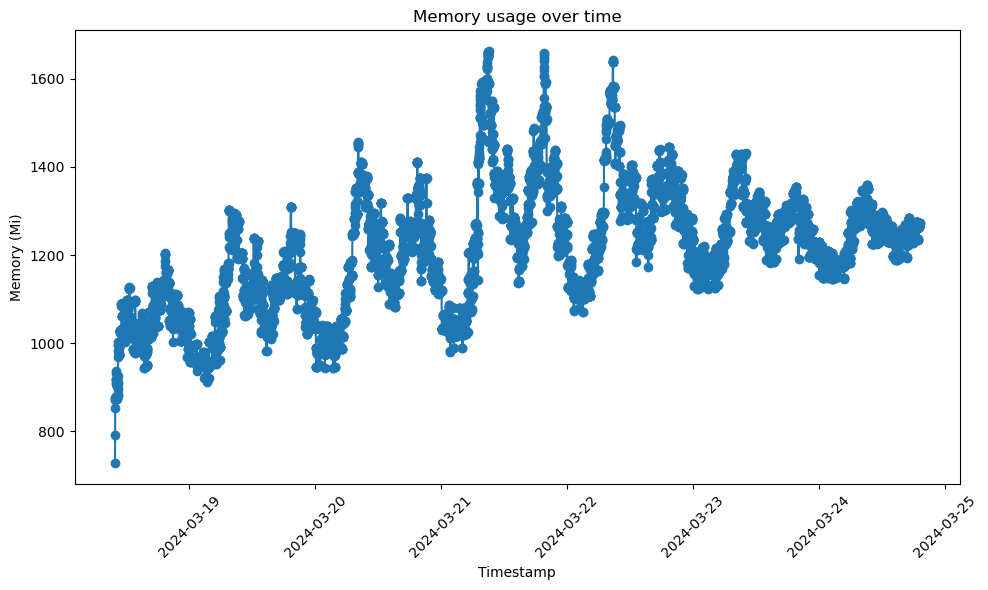

In [2]:
plt.figure(figsize=(10, 6))
plt.plot(node_stats.sort_values(by='Timestamp')['Timestamp'], node_stats['Memory'], marker='o', linestyle='-')
plt.title('Memory usage over time')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()

## Initial Analyses

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

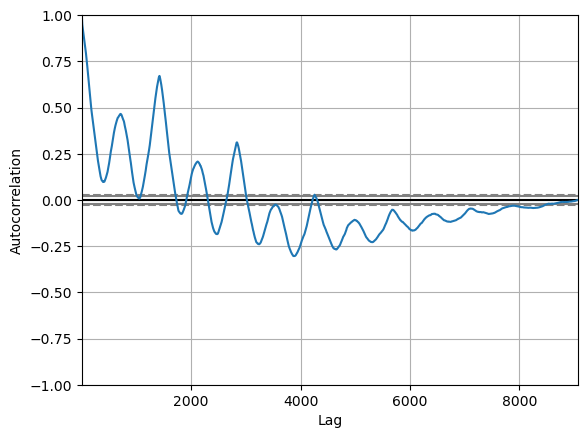

In [3]:
from pandas.plotting import autocorrelation_plot

autocorrelation_plot(node_stats['Memory'])


In [10]:
from statsmodels.tsa.arima.model import ARIMA

node_mem_full = node_stats[['Timestamp', 'Memory']]
node_mem_full = node_mem_full.set_index('Timestamp')
node_mem_full.index = node_mem_full.index.to_period('min')
node_mem_full

,Memory
Timestamp,
2024-03-18 09:48,728
2024-03-18 09:49,792
2024-03-18 09:50,854
2024-03-18 09:51,872
2024-03-18 09:52,875
...,...
2024-03-24 19:10,1273
2024-03-24 19:11,1272
2024-03-24 19:12,1271


<Axes: xlabel='Timestamp'>

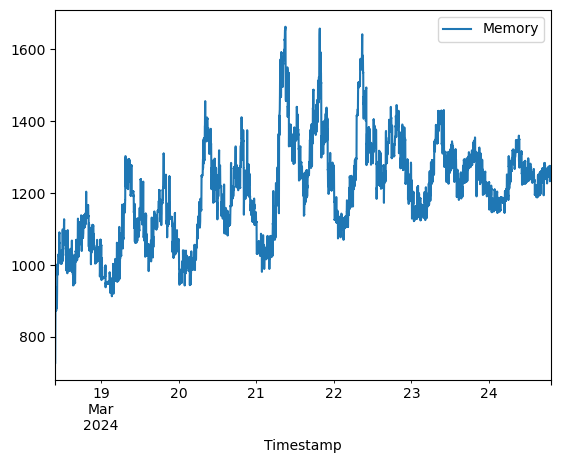

In [11]:
node_mem_full.plot()

We drop the first few rows to get rid of the anomalous data from the cluster ramping up.

<Axes: xlabel='Timestamp'>

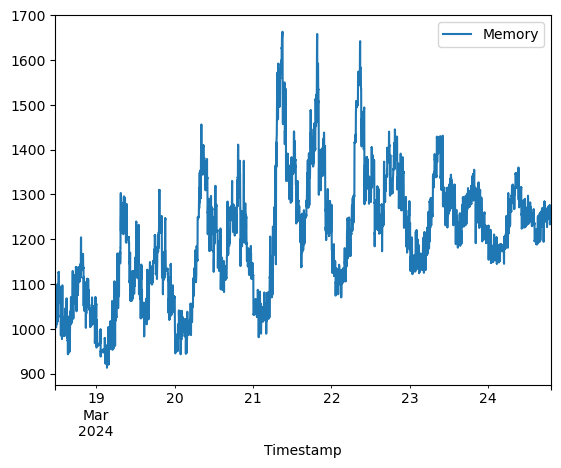

In [12]:
node_mem = node_mem_full.drop(node_mem_full.index[:100])

node_mem.plot()

In [16]:
arima_model = ARIMA(node_mem, order=(5,1,1))
arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                 Memory   No. Observations:                 8971
Model:                 ARIMA(5, 1, 1)   Log Likelihood              -38081.784
Date:                Wed, 01 May 2024   AIC                          76177.568
Time:                        20:08:52   BIC                          76227.279
Sample:                    03-18-2024   HQIC                         76194.486
                         - 03-24-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7646      0.019     40.557      0.000       0.728       0.802
ar.L2         -0.0042      0.012     -0.338      0.735      -0.029       0.020
ar.L3         -0.0217      0.014     -1.564      0.1

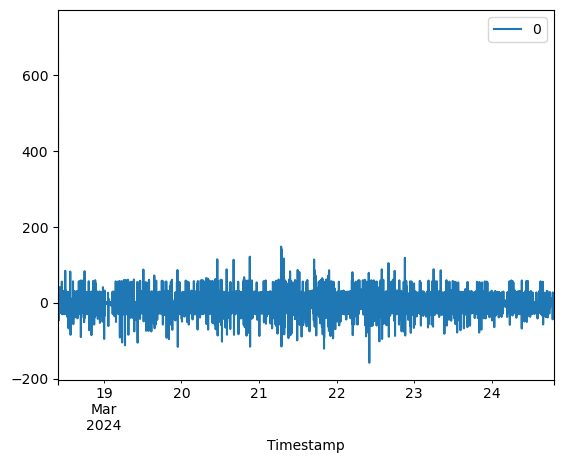

In [6]:
residuals = pd.DataFrame(arima_fit.resid)
residuals.plot()
plt.show()

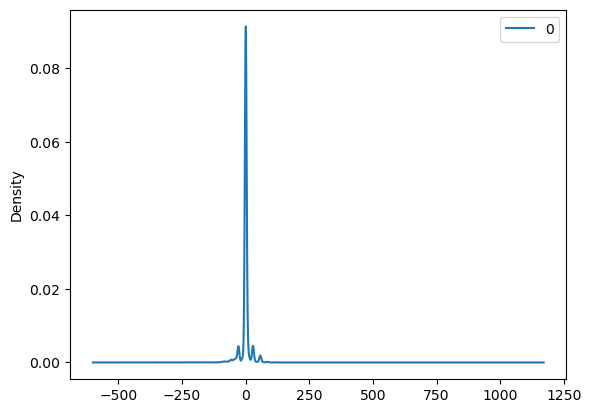

In [7]:
residuals.plot(kind='kde')
plt.show()

In [8]:
node_mem.describe()

,Memory
count,9071.000000
mean,1206.225223
std,136.287644
min,728.000000
25%,1110.000000
50%,1216.000000
75%,1291.000000
max,1663.000000


<Axes: xlabel='Lag', ylabel='Autocorrelation'>

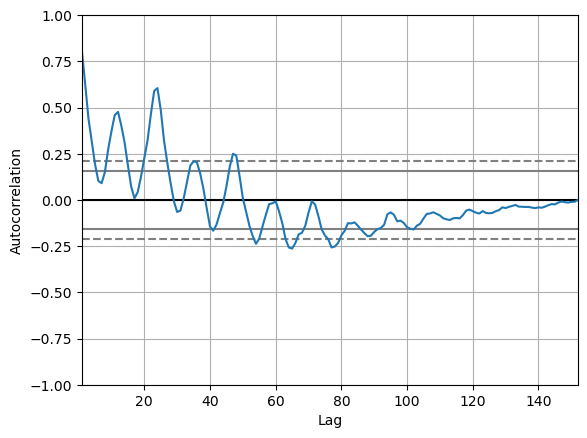

In [34]:
from pandas.plotting import autocorrelation_plot

autocorrelation_plot(node_stats['Memory'].iloc[::60])

## Modeling

Here we subsample every 100 rows.

In [233]:
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

X_vals = node_mem.iloc[::100].copy()
train_size = int(X_vals.shape[0] * 0.9)

X_train, X_test = X_vals.iloc[0:train_size], X_vals.iloc[train_size:X_vals.shape[0]]

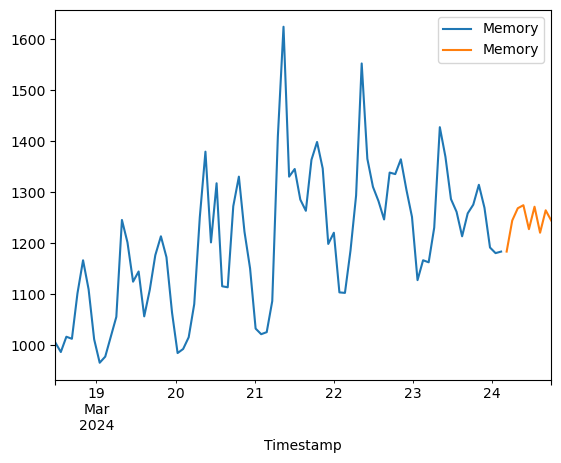

In [211]:
fig, ax = plt.subplots()
X_train.plot(ax=ax, label='train')
X_test.plot(ax=ax, label='test')
plt.legend()
plt.show()

### Testing for Stationarity

In [212]:
adf_result = adfuller(X_train)
print('ADF Statistic: %f' % adf_result[0])
print('p-value: %f' % adf_result[1])

ADF Statistic: -1.712798
p-value: 0.424531


p-value is greater than 0.05, so it's not stationary. We difference once to try to achieve stationarity.

In [213]:
X_train_diff = X_train.diff().dropna()

In [214]:
adf_result1 = adfuller(X_train_diff)
print('ADF Statistic: %f' % adf_result1[0])
print('p-value: %f' % adf_result1[1])

ADF Statistic: -9.182700
p-value: 0.000000


p-value is negligible. We achieved stationarity after 1 degree of differencing.

### Autocorrelation and Partial Autocorrelation

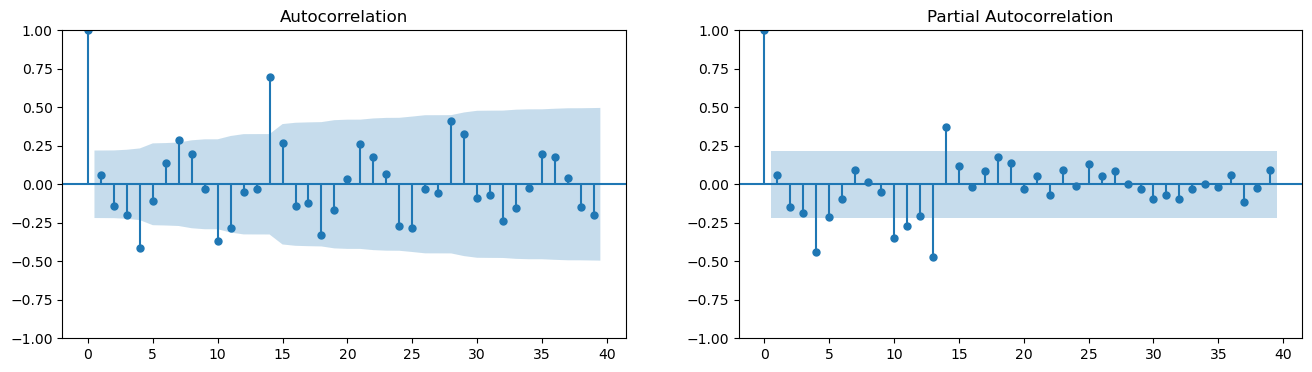

In [215]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(X_train_diff, ax=ax[0], lags=39)
plot_pacf(X_train_diff, ax=ax[1], lags=39)
plt.show()

### Model Training and Evaluation

In [228]:
model = ARIMA(X_train, order=(15,1,15))
model_fit = model.fit()

#predictions = model_fit.predict(start=X_test.index[0].to_timestamp(), end=X_test.index[-1].to_timestamp())
predictions = [model_fit.predict(period) for period in X_test.index]
predictions = pd.concat(predictions)
print(len(predictions))

C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


9


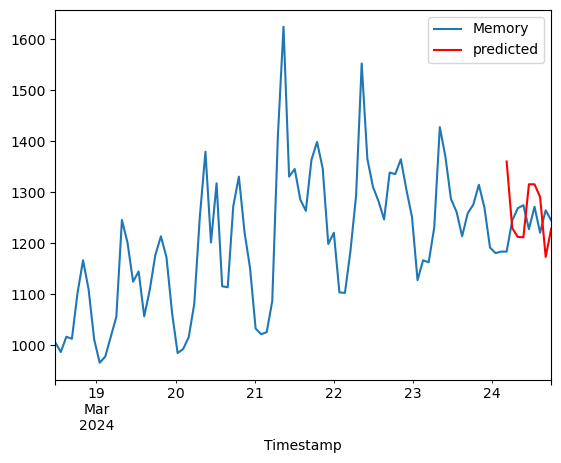

In [229]:
fig, ax = plt.subplots()
pd.concat((X_train, X_test)).plot(ax=ax, label='train')
#X_test.plot(ax=ax, label='actual')
predictions.plot(ax=ax, color='red', label='predicted')
#plt.xlim(X_train.index[-10], X_test.index[-1])
plt.legend()
plt.show()

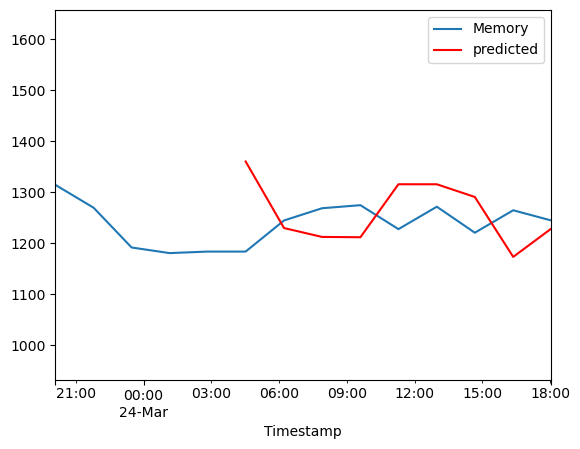

In [223]:
fig, ax = plt.subplots()
pd.concat((X_train, X_test)).plot(ax=ax, label='train')
predictions.plot(ax=ax, color='red', label='predicted')
plt.xlim(X_train.index[-5], X_test.index[-1])
plt.legend()
plt.show()

### SARIMAX

In [237]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(X_train, order=(15,1,15), seasonal_order=(0, 0, 0, 14))
model_fit = model.fit()

predictions = [model_fit.predict(period) for period in X_test.index]
predictions = pd.concat(predictions)
print(len(predictions))

C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\libow\Programs\Anaconda\anaconda3\envs\datasci\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


9


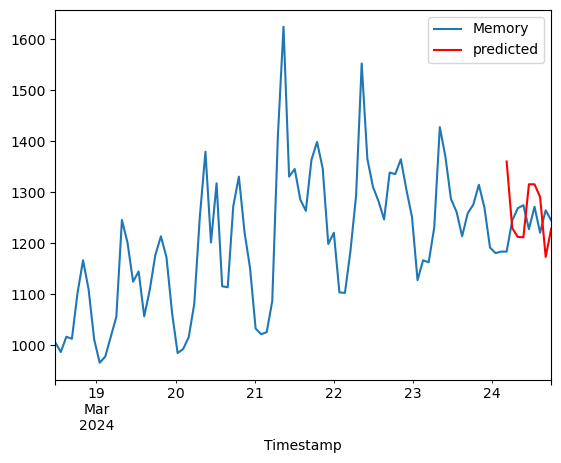

In [238]:
fig, ax = plt.subplots()
pd.concat((X_train, X_test)).plot(ax=ax, label='train')
#X_test.plot(ax=ax, label='actual')
predictions.plot(ax=ax, color='red', label='predicted')
#plt.xlim(X_train.index[-10], X_test.index[-1])
plt.legend()
plt.show()

### Rolling Forecast

#### Baseline

TOTAL ITER: 898
predicted=1184.000000, expected=1185.000000
predicted=1222.000000, expected=1220.000000
predicted=1321.000000, expected=1321.000000
predicted=1327.000000, expected=1327.000000
predicted=1230.000000, expected=1230.000000
predicted=1265.000000, expected=1265.000000
predicted=1198.000000, expected=1198.000000
predicted=1197.000000, expected=1199.000000
predicted=1265.000000, expected=1264.000000
Test RMSE: 12.044


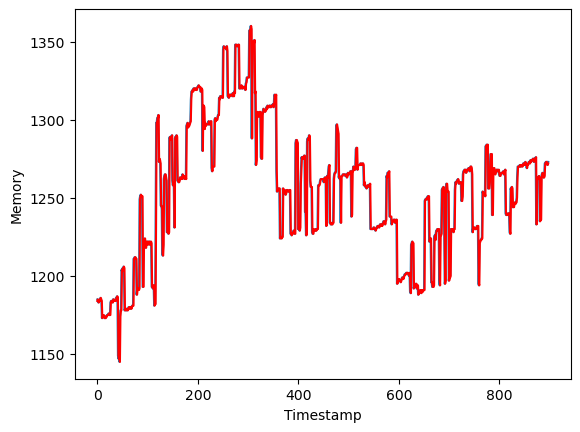

In [17]:
from sklearn.metrics import mean_squared_error

X_vals = node_mem.values
train_size = int(X_vals.shape[0] * 0.9)

X_train, X_test = X_vals[0:train_size], X_vals[train_size:X_vals.shape[0]]

history = [x for x in X_train]
predictions = list()

print("TOTAL ITER:", X_test.shape[0])

PRINT_EVERY = 100
for t in range(X_test.shape[0]):
    output = history[-1]
    predictions.append(output[0])
    obs = X_test[t]
    history.append(obs)
    if t % PRINT_EVERY == 0:
        print('predicted=%f, expected=%f' % (output[0], obs))

rmse = np.sqrt(mean_squared_error(X_test, predictions))
print('Test RMSE: %.3f' % rmse)
plt.plot(X_test)
plt.plot(predictions, color='red')
plt.xlabel("Forecast Step")
plt.ylabel("Memory")
plt.show()

#### Rolling Forecast with ARIMA(5,1,0)

TOTAL ITER: 898
predicted=1184.257020, expected=1185.000000
predicted=1222.218543, expected=1220.000000
predicted=1320.915252, expected=1321.000000
predicted=1326.572505, expected=1327.000000
predicted=1230.631822, expected=1230.000000
predicted=1264.918802, expected=1265.000000
predicted=1198.699977, expected=1198.000000
predicted=1197.864642, expected=1199.000000
predicted=1265.047452, expected=1264.000000
Test RMSE: 11.903


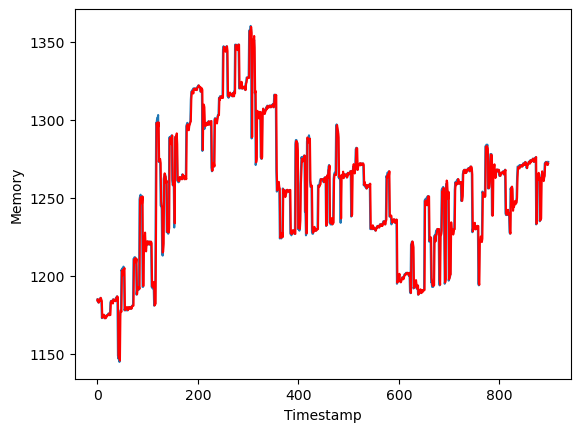

In [240]:
X_vals = node_mem.values
train_size = int(X_vals.shape[0] * 0.9)

X_train, X_test = X_vals[0:train_size], X_vals[train_size:X_vals.shape[0]]

history = [x for x in X_train]
predictions = list()

print("TOTAL ITER:", X_test.shape[0])

PRINT_EVERY = 100
for t in range(X_test.shape[0]):
    model = ARIMA(history, order=(5,1,0))
    model_fit = model.fit()
    output = model_fit.forecast()
    predictions.append(output[0])
    obs = X_test[t]
    history.append(obs)
    if t % PRINT_EVERY == 0:
        print('predicted=%f, expected=%f' % (output[0], obs))

rmse = np.sqrt(mean_squared_error(X_test, predictions))
print('Test RMSE: %.3f' % rmse)
plt.plot(X_test)
plt.plot(predictions, color='red')
plt.xlabel("Timestamp")
plt.ylabel("Memory")
plt.show()